## Final Model

### Random Forest Model

In [1]:
#Import the requires modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

#Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

#Evaluation
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

#Explainability
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import Image

In [2]:
#Import data
df = pd.read_csv('../01_data/model_df.csv')
df.head()

,age,job,marital,education,default,housing,loan,contact,day,month,poutcome,y,contacted_before,balance_log,campaign_log,previous_log,age_bucket,balance_positive,long_campaign
0,58,management,married,tertiary,0,1,0,unknown,5,may,unknown,0,0,9.226607,0.693147,0.0,senior,1,0
1,44,technician,single,secondary,0,1,0,unknown,5,may,unknown,0,0,8.993427,0.693147,0.0,middle,1,0
2,33,entrepreneur,married,secondary,0,1,1,unknown,5,may,unknown,0,0,8.990068,0.693147,0.0,middle,1,0
3,47,blue-collar,married,unknown,0,1,0,unknown,5,may,unknown,0,0,9.161885,0.693147,0.0,middle,1,0
4,33,unknown,single,unknown,0,0,0,unknown,5,may,unknown,0,0,8.989943,0.693147,0.0,middle,1,0


In [3]:
#Split data
X = df.drop('y', axis = 1)
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [5]:
#Define numeric features that need to be scaled and categorical featurs that need OneHotEncoding
numeric_features = ['age', 'balance_log', 'previous_log']
categorical_features = [
    "job","education","marital","contact","poutcome", "day", "month","age_bucket"
]

#Create a preprocessing transformer variable
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown = 'ignore'), categorical_features)
    ]
)
#Train split data on pipeline
pipeline_rfc = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state = 42)),
    ('classifier', RandomForestClassifier(random_state = 42, n_jobs = -1))
])

pipeline_rfc.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'balance_log',
                                                   'previous_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'education',
                                                   'marital', 'contact',
                                                   'poutcome', 'day', 'month',
                                                   'age_bucket'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [6]:
#Define hyperparamter search space - dictionary for the hyperparameter to tune and each value for a lost of possible settings to explore
param_dist_rfc = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__max_features': ['sqrt']
}

#Set up randomsearchcv
random_search_rfc = RandomizedSearchCV(
    estimator = pipeline_rfc,
    param_distributions = param_dist_rfc,
    n_iter = 16,
    cv = 3, #uses 3-fold cross-validation
    random_state = 42
)

#Fit the tuning process
random_search_rfc.fit(X_train, y_train)

#Print the results
print(random_search_rfc.best_params_)
print(random_search_rfc.best_score_)

#Find the best results from randomized search and make predictions based on these parameters
best_model_rfc = random_search_rfc.best_estimator_
y_pred_rfc = best_model_rfc.predict(X_test)

{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}
0.8777796216395619


### Evaluation

In [7]:
#Print evaluation metrics
print(classification_report(y_test, y_pred_rfc))

              precision    recall  f1-score   support

           0       0.92      0.93      0.93      7942
           1       0.46      0.43      0.45      1097

    accuracy                           0.87      9039
   macro avg       0.69      0.68      0.69      9039
weighted avg       0.87      0.87      0.87      9039



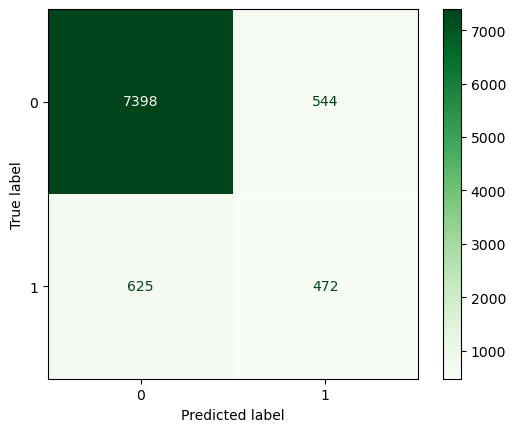

In [8]:
#Print confusion matrix
cm = confusion_matrix(y_test, y_pred_rfc)
ConfusionMatrixDisplay(confusion_matrix = cm).plot(cmap=plt.cm.Greens)

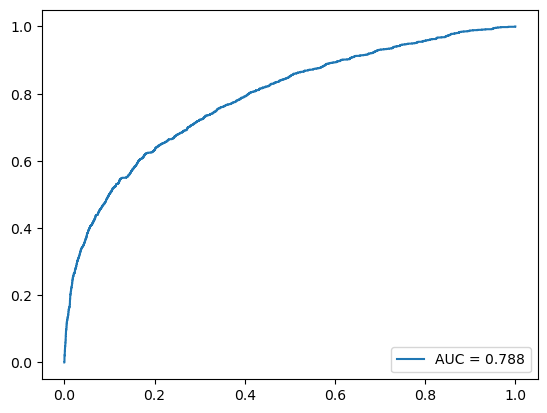

In [9]:
#Print ROC-AUC curve
y_pred_proba_rfc = best_model_rfc.predict_proba(X_test)[:,1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba_rfc)
auc = metrics.roc_auc_score(y_test, y_pred_proba_rfc)

plt.plot(fpr, tpr, label = "AUC = "+ str(round(auc,3)))
plt.legend(loc = 4)
plt.show()

### Explainabilitiy

#### Feature Importance

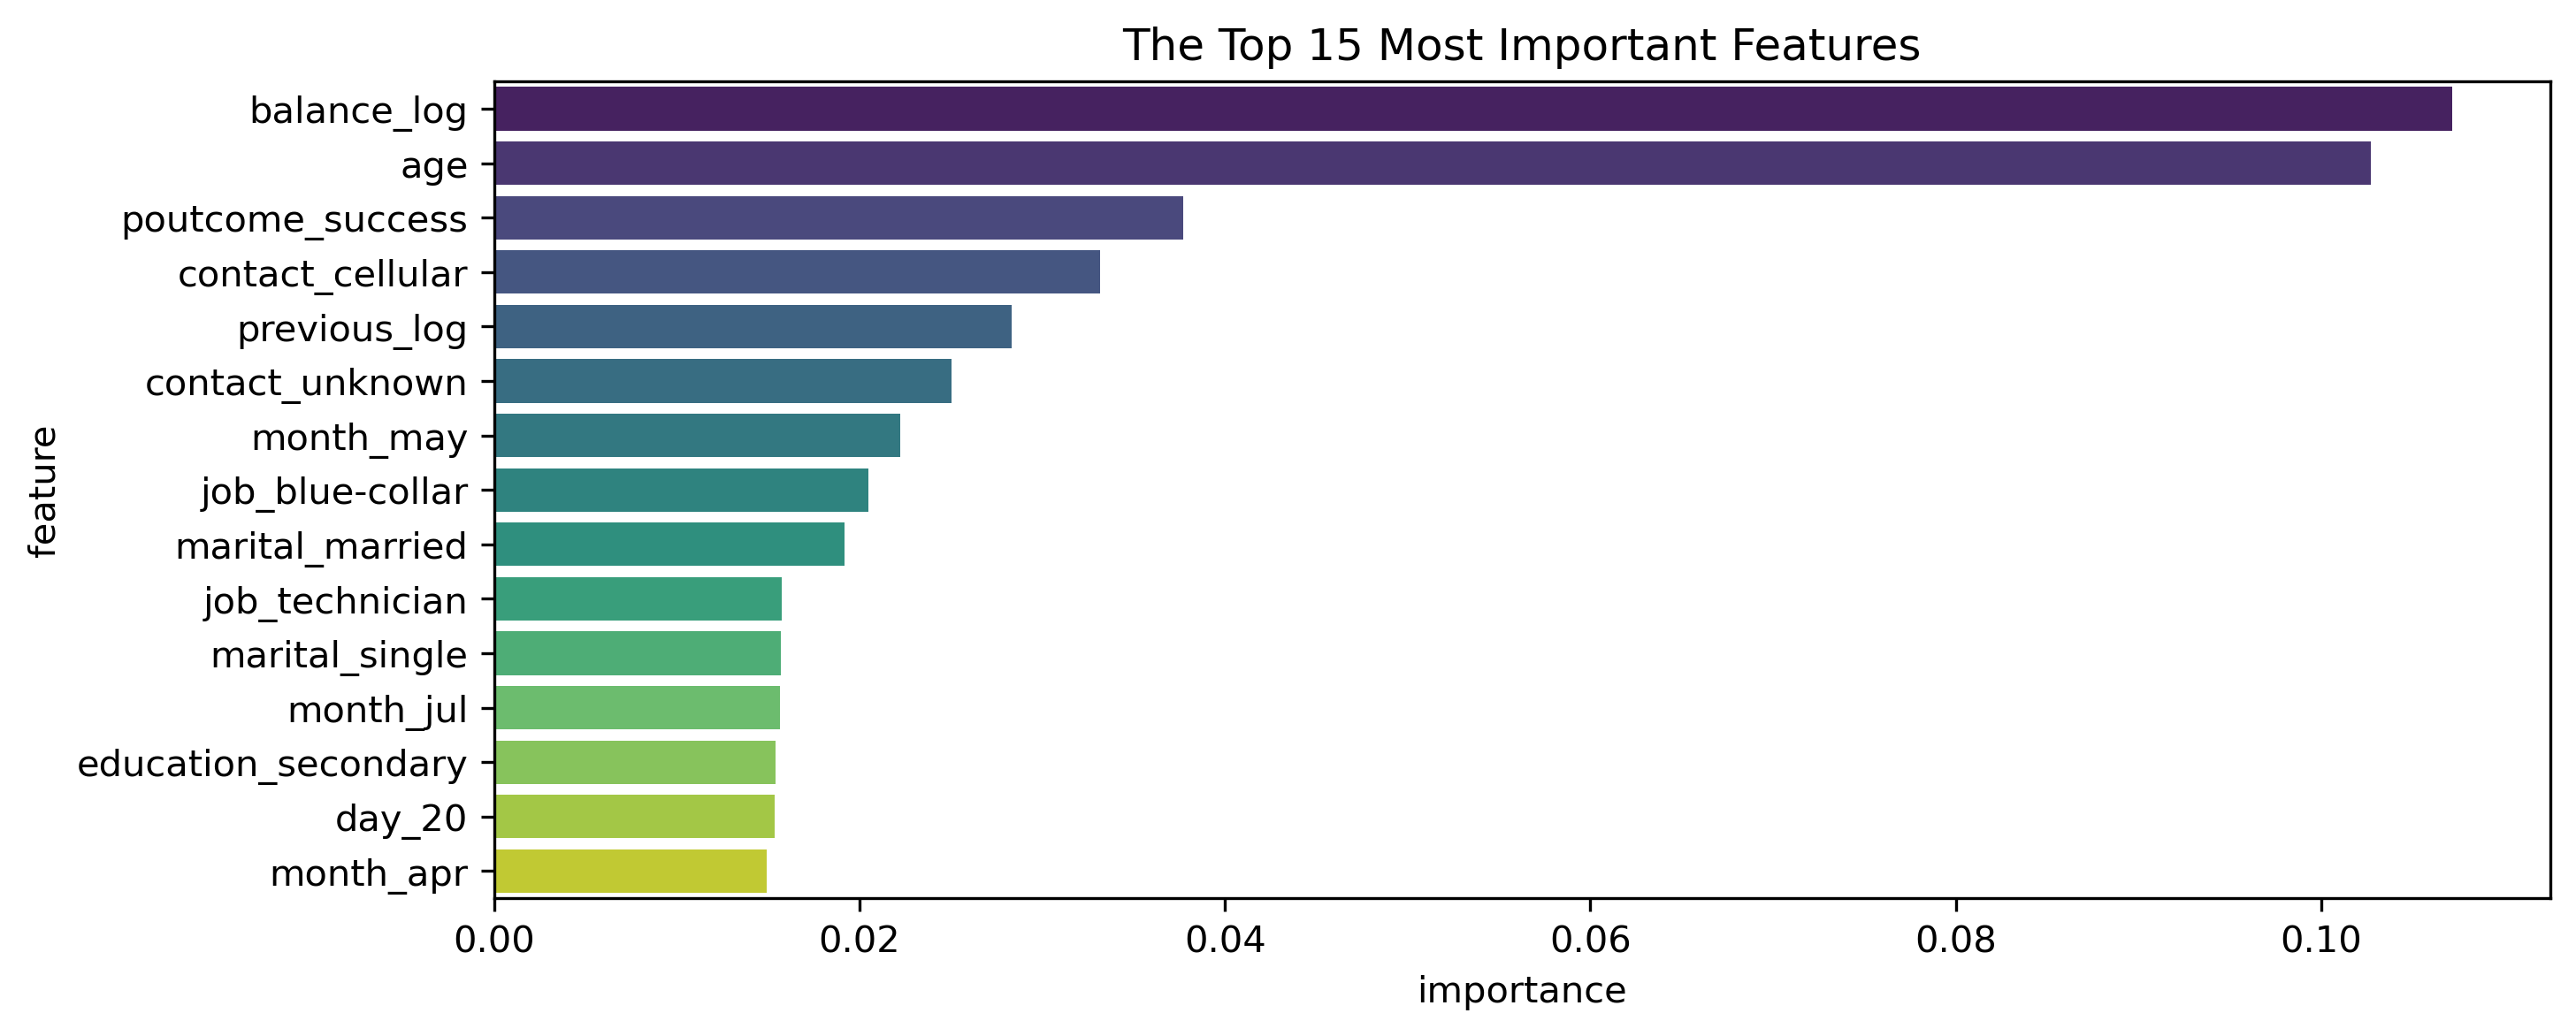

In [10]:
#Get Feature names

#Get numeric features
num_features = numeric_features

#Get names of the categorical features after one-hot encoding
cat_features = pipeline_rfc.named_steps['preprocess'].named_transformers_['cat'].get_feature_names_out(categorical_features)

#Combine the names of all the features
all_features = np.concatenate([num_features, cat_features])

#Extract the feature importance values
importance = pipeline_rfc.named_steps['classifier'].feature_importances_

#Create a DataFrame
fi_df = pd.DataFrame({
    'feature': all_features,
    'importance': importance
}).sort_values('importance', ascending = False)

#Plot
plt.figure(figsize = (10,4), dpi = 300)
sns.barplot(data = fi_df.head(15), 
            x = 'importance',
            y = 'feature',
            hue = 'feature',
            palette = 'viridis')

plt.title('The Top 15 Most Important Features')
plt.show()

#### LIME Explainability

In [11]:
#Get numeric data
X_train_transformed = pipeline_rfc.named_steps['preprocess'].transform(X_train)
feature_names = pipeline_rfc.named_steps['preprocess'].get_feature_names_out()

explainer = LimeTabularExplainer(
    X_train_transformed,
    feature_names = feature_names,
    class_names = [0,1],
    mode = 'classification'
)

def predict_proba_transformed(x):
    return pipeline_rfc.named_steps['classifier'].predict_proba(x)

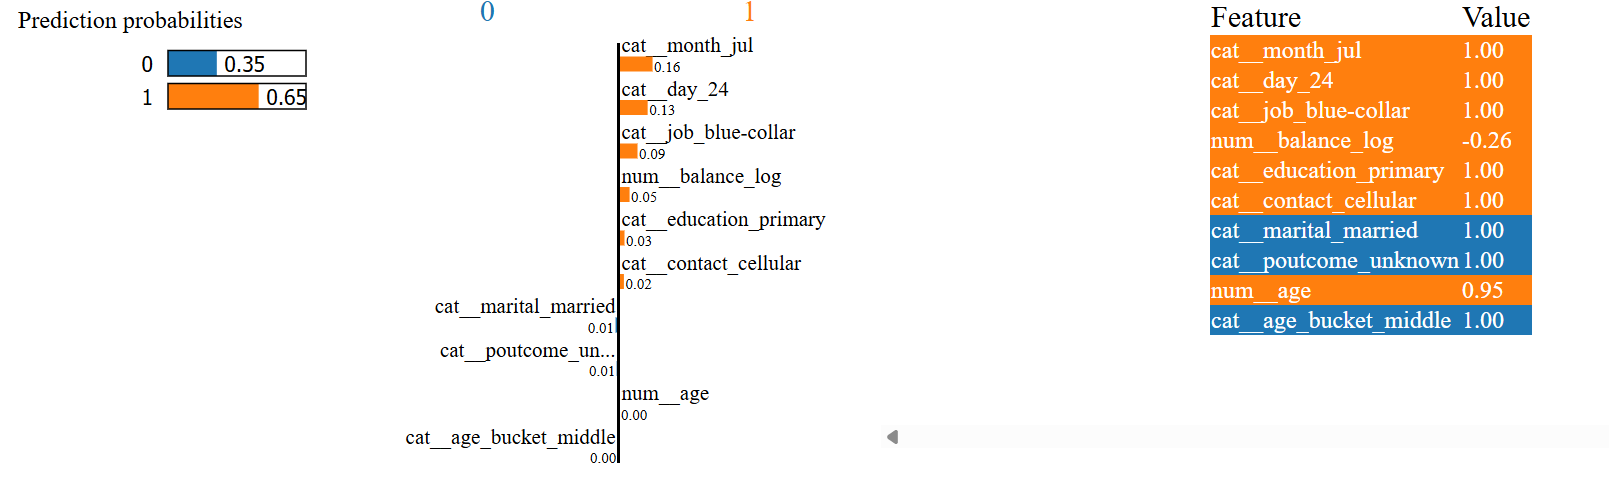

In [12]:
#Correctly predicted case
i = np.where((y_train == 1) & (pipeline_rfc.predict(X_train) == 1))[0][0]
exp = explainer.explain_instance(
    X_train_transformed[i],
    predict_proba_transformed
)

#exp.show_in_notebook()
Image("lime_explanation_correct_prediction.png")

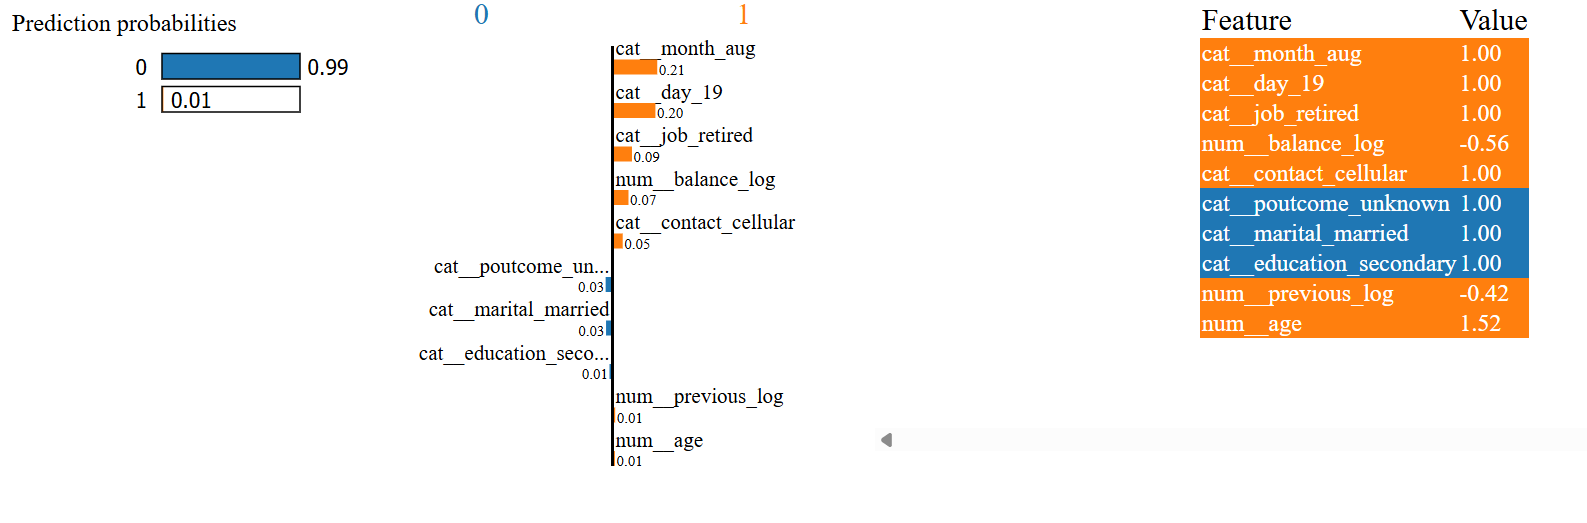

In [13]:
#A misclassified case - false negatives
false_negatives = np.where((y_test == 1) & (y_pred_rfc == 0))[0]
i = false_negatives[0]
X_test_transformed = pipeline_rfc.named_steps['preprocess'].transform(X_test)
exp = explainer.explain_instance(
    X_train_transformed[i],
    predict_proba_transformed
)

#exp.show_in_notebook()
Image("lime_explanation_false_negative.png")